# Hand-Designed Grid

9 hand-designed circuits on the first 8 and best 8, 3 seeds each, scored on val. then the short-training setting that ranks circuits most like full training.

In [1]:
!pip install -q pennylane==0.45.1

import os
os.environ["OMP_NUM_THREADS"] = "1"
import time
import json
import multiprocessing as mp
import numpy as np
import pandas as pd
import torch
import pennylane as qml
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

seed = 0
np.random.seed(seed)
torch.set_num_threads(1)

prep_dir = "/kaggle/input/datasets/malakkhaled202300369/nic-feature-dataset/prep"
out_dir = "/kaggle/working/grid"
os.makedirs(out_dir, exist_ok=True)

seeds = [0, 1, 2]
# full training, picked in the first circuit notebook
lr = 0.01
epochs = 5
batch_size = 256
short_options = [(0.01, 3), (0.03, 3), (0.1, 3), (0.01, 6), (0.03, 6), (0.1, 6)]   # (lr, epochs), batch 100
lam = 0.0006        # fitness penalty per two-qubit gate
tie_margin = 0.05   # settings this close to the best ranking count as tied, the cheapest wins

In [2]:
angles = {}
meta = {}
for split in ["train", "val"]:
    angles[split] = np.load(f"{prep_dir}/ffpp_{split}_angles32.npy").astype(np.float64)
    meta[split] = pd.read_csv(f"{prep_dir}/ffpp_{split}_rows.csv")

is_inner = np.load(f"{prep_dir}/ffpp_train_is_inner.npy").astype(bool)
comp = pd.read_csv(f"{prep_dir}/per_component_auc.csv")
best8 = sorted(comp.sort_values("strength_search_train", ascending=False)["component"].head(8).tolist())
first8 = list(range(8))

y_train = meta["train"]["label"].to_numpy()
y_val = meta["val"]["label"].to_numpy()
# a video is (method, video_id), the 4 fakes of one pair share a video_id
val_video = meta["val"].groupby(["method", "video_id"]).ngroup().to_numpy()

## fitness frames

the search trains each genome on 2000 search-train frames (1000 real, 1000 fake, at most 2 per real video and 1 per fake video) and scores it by auc on the inner fitness frames.

In [3]:
search_idx = np.where(~is_inner)[0]
inner_idx = np.where(is_inner)[0]

st = meta["train"].iloc[search_idx].copy()
st["row"] = search_idx
real_pick = st[st["label"] == 0].groupby("video_id").sample(n=2, random_state=0)["row"].to_numpy()
fake_pick = st[st["label"] == 1].groupby(["method", "video_id"]).sample(n=1, random_state=0)["row"].to_numpy()
rng = np.random.default_rng(0)
sub = np.concatenate([rng.choice(real_pick, 1000, replace=False), rng.choice(fake_pick, 1000, replace=False)])

## the circuit from a genome

a genome is the 8 components (to qubits 0 to 7 in ascending order), the encoding, and per layer a rotation and an entangler. readout is <z> on all 8 qubits, then a weighted sum and a bias.

In [4]:
n_qubits = 8
gates_per_layer = {"none": 0, "chain": n_qubits - 1, "ring": n_qubits, "cz_ring": n_qubits}
angles_per_rot = {"RY": 1, "RX+RY": 2, "Rot": 3}


def make_genome(mask, encoding, layers):
    return {"mask": sorted(mask), "encoding": encoding, "layers": [{"rotation": r, "entangler": e} for r, e in layers]}


def two_qubit_gates(g):
    return sum(gates_per_layer[layer["entangler"]] for layer in g["layers"])


def n_weights(g):
    return sum(n_qubits * angles_per_rot[layer["rotation"]] for layer in g["layers"]) + n_qubits + 1


def build_circuit(g):
    dev = qml.device("default.qubit", wires=n_qubits)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, ws):
        for i in range(n_qubits):
            if g["encoding"] == "RX":
                qml.RX(x[:, i], wires=i)
            elif g["encoding"] == "RY":
                qml.RY(x[:, i], wires=i)
            else:
                qml.Hadamard(wires=i)
                qml.RZ(x[:, i], wires=i)
        for layer, w in zip(g["layers"], ws):
            for i in range(n_qubits):
                if layer["rotation"] == "RY":
                    qml.RY(w[i, 0], wires=i)
                elif layer["rotation"] == "RX+RY":
                    qml.RX(w[i, 0], wires=i)
                    qml.RY(w[i, 1], wires=i)
                else:
                    qml.Rot(w[i, 0], w[i, 1], w[i, 2], wires=i)
            if layer["entangler"] == "chain":
                for i in range(n_qubits - 1):
                    qml.CNOT(wires=[i, i + 1])
            elif layer["entangler"] == "ring":
                for i in range(n_qubits):
                    qml.CNOT(wires=[i, (i + 1) % n_qubits])
            elif layer["entangler"] == "cz_ring":
                for i in range(n_qubits):
                    qml.CZ(wires=[i, (i + 1) % n_qubits])
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

    return circuit


class QuantumClassifier(torch.nn.Module):
    def __init__(self, g):
        super().__init__()
        self.circuit = build_circuit(g)
        self.rot = torch.nn.ParameterList()
        for layer in g["layers"]:
            k = angles_per_rot[layer["rotation"]]
            self.rot.append(torch.nn.Parameter(0.1 * torch.randn(n_qubits, k, dtype=torch.float64)))
        self.readout = torch.nn.Linear(n_qubits, 1, dtype=torch.float64)
        torch.nn.init.normal_(self.readout.weight, std=0.1)
        torch.nn.init.zeros_(self.readout.bias)

    def forward(self, x):
        out = torch.stack(self.circuit(x, list(self.rot)), dim=1).to(torch.float64)
        return self.readout(out).squeeze(1)


def train(model, x, y, lr=0.01, epochs=5, batch_size=256, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.as_tensor(x, dtype=torch.float64)
    y = torch.as_tensor(y, dtype=torch.float64)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = torch.nn.BCEWithLogitsLoss()
    for epoch in range(epochs):
        order = torch.randperm(len(x), generator=g)
        for start in range(0, len(x), batch_size):
            idx = order[start:start + batch_size]
            opt.zero_grad()
            loss_fn(model(x[idx]), y[idx]).backward()
            opt.step()


def predict(model, x, batch_size=4096):
    out = []
    with torch.no_grad():
        for s in range(0, len(x), batch_size):
            xb = torch.as_tensor(x[s:s + batch_size], dtype=torch.float64)
            out.append(torch.sigmoid(model(xb)))
    return torch.cat(out).numpy()

In [5]:
def video_level(prob):
    df = pd.DataFrame({"video": val_video, "p": prob, "y": y_val})
    g = df.groupby("video").agg(p=("p", "mean"), y=("y", "first"))
    return g["p"].to_numpy(), g["y"].to_numpy()


def bootstrap_ci(p, y, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    aucs = []
    while len(aucs) < n:
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        aucs.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(aucs, [2.5, 97.5])


def score(prob):
    pv, yv = video_level(prob)
    lo, hi = bootstrap_ci(pv, yv)
    return {"frame auc": roc_auc_score(y_val, prob), "video auc": roc_auc_score(yv, pv), "ci low": lo, "ci high": hi}

In [6]:
grid = []
for mask_name, mask in [("first 8", first8), ("best 8", best8)]:
    for depth in [1, 2, 3]:
        for ent in ["none", "chain", "ring"]:
            g = make_genome(mask, "RY", [("Rot", ent)] * depth)
            grid.append({"circuit": f"{mask_name}, depth {depth}, {ent}", "mask": mask_name, "depth": depth,
                         "entangler": ent, "genome": g, "weights": n_weights(g), "gates": two_qubit_gates(g)})

## run everything in parallel

one task is a full training (circuit x seed) or a short training (circuit x setting), one process per core, longest first.

In [7]:
def run_task(task):
    kind, i, value = task
    g = grid[i]["genome"]
    cols = g["mask"]
    t0 = time.time()
    if kind == "full":
        torch.manual_seed(value)
        model = QuantumClassifier(g)
        train(model, angles["train"][:, cols], y_train, lr=lr, epochs=epochs, batch_size=batch_size, seed=value)
        row = {"kind": kind, "i": i, "seed": value}
        row.update(score(predict(model, angles["val"][:, cols])))
    else:
        short_lr, short_epochs = value
        torch.manual_seed(0)
        model = QuantumClassifier(g)
        train(model, angles["train"][sub][:, cols], y_train[sub], lr=short_lr, epochs=short_epochs, batch_size=100, seed=0)
        auc = roc_auc_score(y_train[inner_idx], predict(model, angles["train"][inner_idx][:, cols]))
        row = {"kind": kind, "i": i, "lr": short_lr, "epochs": short_epochs, "inner auc": auc}
    row["seconds"] = time.time() - t0
    return row


tasks = []
for i in range(len(grid)):
    for s in seeds:
        tasks.append(("full", i, s))
    for o in short_options:
        tasks.append(("short", i, o))
tasks.sort(key=lambda t: (t[0] != "full", -grid[t[1]]["depth"], -grid[t[1]]["gates"]))

with mp.get_context("fork").Pool(os.cpu_count()) as pool:
    results = pool.map(run_task, tasks)

## grid results on val

mean and spread over the 3 seeds. the best circuit's worst-seed interval should sit above 0.5.

                circuit  weights  gates  video auc mean  video auc std  frame auc mean  ci low worst  minutes per run
 first 8, depth 1, none       33      0           0.641          0.001           0.617         0.588            1.474
first 8, depth 1, chain       33      7           0.630          0.004           0.615         0.579            1.648
 first 8, depth 1, ring       33      8           0.628          0.021           0.613         0.552            1.680
 first 8, depth 2, none       57      0           0.642          0.001           0.617         0.590            2.751
first 8, depth 2, chain       57     14           0.644          0.005           0.626         0.586            3.211
 first 8, depth 2, ring       57     16           0.645          0.005           0.627         0.592            3.223
 first 8, depth 3, none       81      0           0.641          0.001           0.617         0.587            3.699
first 8, depth 3, chain       81     21           0.646 

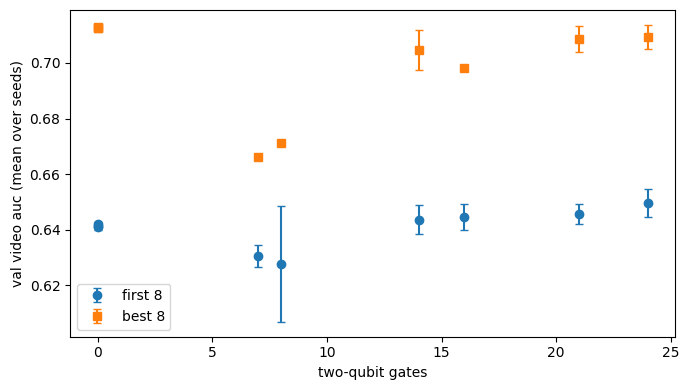

In [8]:
full = pd.DataFrame([r for r in results if r["kind"] == "full"])
full["circuit"] = [grid[i]["circuit"] for i in full["i"]]
full.drop(columns=["kind"]).to_csv(f"{out_dir}/grid_runs.csv", index=False)

summary = []
for i, c in enumerate(grid):
    f = full[full["i"] == i]
    summary.append({"circuit": c["circuit"], "mask": c["mask"], "depth": c["depth"], "entangler": c["entangler"],
                    "weights": c["weights"], "gates": c["gates"],
                    "video auc mean": f["video auc"].mean(), "video auc std": f["video auc"].std(),
                    "frame auc mean": f["frame auc"].mean(), "ci low worst": f["ci low"].min(),
                    "minutes per run": f["seconds"].mean() / 60})
summary = pd.DataFrame(summary)
summary.to_csv(f"{out_dir}/grid_summary.csv", index=False)
print(summary.drop(columns=["mask", "depth", "entangler"]).round(3).to_string(index=False))

best = summary.sort_values("video auc mean", ascending=False).iloc[0]
print(f"best: {best['circuit']}, video auc {best['video auc mean']:.3f}, worst-seed interval low {best['ci low worst']:.3f}")

plt.figure(figsize=(7, 4))
for m, marker in [("first 8", "o"), ("best 8", "s")]:
    s = summary[summary["mask"] == m]
    plt.errorbar(s["gates"], s["video auc mean"], yerr=s["video auc std"], fmt=marker, capsize=3, label=m)
plt.xlabel("two-qubit gates")
plt.ylabel("val video auc (mean over seeds)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/grid_front.png", dpi=150)
plt.show()

## ranking check

spearman correlation between short-training inner auc and full-training val auc. first 8 against best 8 is easy for every setting, so the pick uses the mean of the two within-input correlations.

In [9]:
short = pd.DataFrame([r for r in results if r["kind"] == "short"])
short["circuit"] = [grid[i]["circuit"] for i in short["i"]]
short.drop(columns=["kind"]).to_csv(f"{out_dir}/short_fitness.csv", index=False)

target = summary["video auc mean"].to_numpy()
check = []
for short_lr, short_epochs in short_options:
    s = short[(short["lr"] == short_lr) & (short["epochs"] == short_epochs)].sort_values("i")
    inner = s["inner auc"].to_numpy()
    first = (summary["mask"] == "first 8").to_numpy()
    row = {"lr": short_lr, "epochs": short_epochs, "spearman all": spearmanr(inner, target)[0],
           "spearman first 8": spearmanr(inner[first], target[first])[0],
           "spearman best 8": spearmanr(inner[~first], target[~first])[0]}
    row["spearman within"] = (row["spearman first 8"] + row["spearman best 8"]) / 2
    row["seconds per eval"] = s["seconds"].mean()
    check.append(row)

check = pd.DataFrame(check)
check.to_csv(f"{out_dir}/ranking_check.csv", index=False)
print(check.round(3).to_string(index=False))

tied = check[check["spearman within"] >= check["spearman within"].max() - tie_margin]
chosen = tied.sort_values("seconds per eval").iloc[0]
print(f"chosen: lr {chosen['lr']}, {int(chosen['epochs'])} epochs")

recipe = {"lr": lr, "epochs": epochs, "batch_size": batch_size, "fit_lr": float(chosen["lr"]),
          "fit_epochs": int(chosen["epochs"]), "fit_batch_size": 100, "lambda": lam, "best8": best8}
with open(f"{out_dir}/recipe.json", "w") as f:
    json.dump(recipe, f, indent=1)

  lr  epochs  spearman all  spearman first 8  spearman best 8  spearman within  seconds per eval
0.01       3         0.748            -0.100            0.917            0.408             7.261
0.03       3         0.796             0.233            0.983            0.608             7.228
0.10       3         0.882             0.317            0.733            0.525             7.207
0.01       6         0.752             0.150            0.900            0.525            12.582
0.03       6         0.864             0.417            0.950            0.683            12.527
0.10       6         0.924             0.517            0.867            0.692            12.456
chosen: lr 0.1, 6 epochs
